In [1]:
	# Load data
import pandas as pd
data = pd.read_csv('..\data\jakarta_house_imputed.csv')
data.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


In [4]:
import pandas as pd
import numpy as np

# 1. Load data CSV-nya dulu (sesuaikan nama file CSV lu)
df = pd.read_csv('../data/jakarta_house_imputed.csv')

# 2. Definisikan X (fitur) dan y (label/target)
# Contoh: y adalah kolom 'price', dan X adalah kolom sisanya
y = df['price'].values
X = df[['land_area', 'building_area', 'bed_rooms', 'bath_rooms']].values

# 3. Baru jalankan kode reshape lu yang tadi
y_new = y.reshape(len(y), 1)

# 4. Gabungkan fitur X dan label y dalam data array
data = np.concatenate((X, y_new), axis=1)

# 5. Definisikan nama kolom (sesuaikan urutannya)
nama_kolom = ['land area', 'building area', 'bedroom', 'bathroom', 'price']

# 6. Buat Data Frame
df_baru = pd.DataFrame(data, columns=nama_kolom)

# 7. Cek Data Frame
df_baru.head()

,land area,building area,bedroom,bathroom,price
0,250.0,350.0,2.0,4.0,5.900000e+09
1,100.0,225.0,4.0,2.0,2.700000e+09
2,60.0,140.0,3.0,3.0,2.200000e+09
3,60.0,120.0,3.0,2.0,1.900000e+09
4,56.0,108.0,4.0,3.0,2.100000e+09


In [6]:
# Cukup copy DataFrame lu tanpa perlu mapping labels kelas A/B
df_label = df.copy()

# Cek 5 baris teratas
df_label.head()

,index,price,district,city,bed_rooms,bath_rooms,carport,land_area,building_area
0,1,5900000000,Citra Garden,Jakarta Barat,2,4,2,250.0,350.0
1,2,2700000000,Jelambar,Jakarta Barat,4,2,0,100.0,225.0
2,3,2200000000,Jelambar,Jakarta Barat,3,3,0,60.0,140.0
3,4,1900000000,Jelambar,Jakarta Barat,3,2,0,60.0,120.0
4,5,2100000000,Tanjung Duren,Jakarta Barat,4,3,0,56.0,108.0


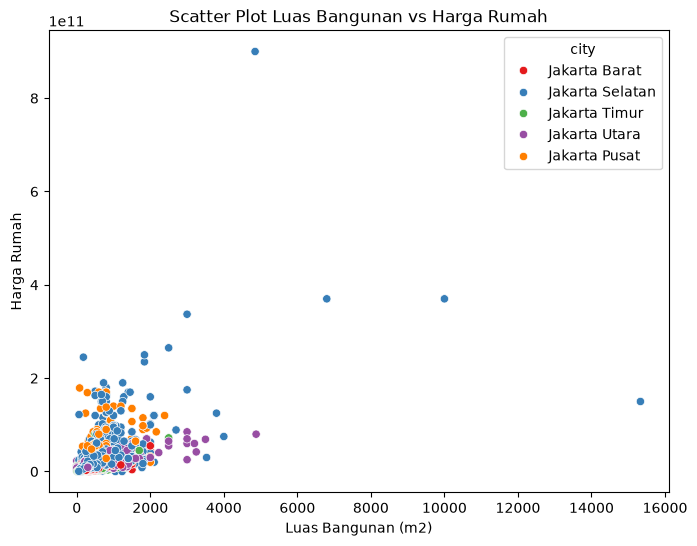

In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

# Bikin scatter plot pakai data rumah lu
plt.figure(figsize=(8, 6))
sns.scatterplot(
    data=df, 
    x='building_area', # Ganti jadi fitur angka yang mau diliat (misal: luas bangunan)
    y='price',         # Targetnya (harga rumah)
    hue='city',        # Warnai titik berdasarkan kota (Jakarta Barat, Selatan, dll.)
    palette='Set1'     # Pilihan palet warna seaborn
)

plt.xlabel('Luas Bangunan (m2)')
plt.ylabel('Harga Rumah')
plt.title('Scatter Plot Luas Bangunan vs Harga Rumah')
plt.show()

In [11]:
import numpy as np
import pandas as pd
from sklearn.naive_bayes import MultinomialNB
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score

# 1. Pastikan dataframe lu bersih dari NaN (isi nilai kosong dengan 0 atau rata-rata)
# Karena MultinomialNB butuh nilai >= 0, isi NaN dengan angka 0 adalah cara paling aman
df_clean = df.fillna(0)

# 2. Tentukan fitur (X) dan target (y)
# (Sesuaikan nama kolom fitur angka dan label target lu ya)
X = df_clean[['land_area', 'building_area', 'bed_rooms', 'bath_rooms']] 
y = df_clean['price'] # Ganti dengan kolom target/label lu

# 3. Normalisasi pakai MinMaxScaler (biar nilainya rentang 0-1, ga ada minus sama sekali)
scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

# 4. Cek darurat: Pastikan sudah 100% bebas NaN dan nilai negatif
print("Jumlah NaN di X_scaled:", np.isnan(X_scaled).sum())
print("Jumlah NaN di y:", y.isna().sum())

# 5. Split data training dan testing
X_train, X_test, y_train, y_test = train_test_split(X_scaled, y, test_size=0.3, random_state=30)

# 6. Inisialisasi dan Latih model MultinomialNB
mnb = MultinomialNB()
mnb.fit(X_train, y_train)

# 7. Evaluasi model
y_train_pred = mnb.predict(X_train)
acc_train = accuracy_score(y_train, y_train_pred)

y_test_pred = mnb.predict(X_test)
acc_test = accuracy_score(y_test, y_test_pred)

print(f'\nHasil akurasi data train: {acc_train}')
print(f'Hasil akurasi data test: {acc_test}')

Jumlah NaN di X_scaled: 0
Jumlah NaN di y: 0

Hasil akurasi data train: 0.02142857142857143
Hasil akurasi data test: 0.02033333333333333


In [12]:
from sklearn.naive_bayes import GaussianNB # class untuk model GaussianNB

# Inisiasi obyek Gaussian
gnb = GaussianNB()

# Kita menggunakan split data training dan testing
# yang sama dengan model multinomial

# Fit model
# Label y harus dalam bentu 1D atau (n_samples,)
gnb.fit(X_train, y_train)

# Prediksi dengan data training
y_train_pred_gnb = gnb.predict(X_train)

# Evaluasi akurasi training
acc_train_gnb = accuracy_score(y_train, y_train_pred_gnb)

# Prediksi test data
y_test_pred_gnb = gnb.predict(X_test)

# Evaluasi model dengan metric akurasi
acc_test_gnb = accuracy_score(y_test, y_test_pred_gnb)

# Print hasil evaluasi
print(f'Hasil akurasi data train (Gaussian): {acc_train_gnb}')
print(f'Hasil akurasi data test (Gaussian): {acc_test_gnb}')

Hasil akurasi data train (Gaussian): 0.06928571428571428
Hasil akurasi data test (Gaussian): 0.013333333333333334
